In [1]:
import random
import datetime
import matplotlib.pyplot as plt

COMPANY = "TeleConnect (a Jio/Airtel-style telecom operator)"
NUM_CUSTOMERS = 60
HIGH_RISK_LIMIT = 60        # score at or above this = High risk
MEDIUM_RISK_LIMIT = 30      # score at or above this = Medium risk
LINE_WIDTH = 78

random.seed(7)              # same random data every time you run it

In [2]:
plan_names = ["Basic", "Standard", "Premium"]
plan_fees = [199, 299, 599]            # monthly fee in Rs
risk_labels = ("Low", "Medium", "High")  # a tuple: these never change


def line(char="-"):
    print(char * LINE_WIDTH)


def header(title):
    print()
    line("=")
    print(f"{title:^{LINE_WIDTH}}")
    line("=")


def average(values):
    total = 0
    for value in values:
        total += value
    return total / len(values)


def std_dev(values):
    """Standard deviation: how spread out the numbers are."""
    mean = average(values)
    squared_sum = 0
    for value in values:
        squared_sum += (value - mean) ** 2
    return (squared_sum / len(values)) ** 0.5


def tenure_text(months):
    """26 months -> '2 yr 2 mo'"""
    return f"{months // 12} yr {months % 12} mo"


def mask_phone(phone):
    """9876543210 -> 98XXXXXX10"""
    return phone[:2] + "X" * 6 + phone[-2:]

In [3]:
def make_phone():
    number = "9"
    for position in range(9):
        number = number + str(random.randint(0, 9))
    return number


customer_ids = []
phones = []
plans = []
fees = []
tenures = []           # months with the company
usage_changes = []     # % change in data usage vs the last 3 months
complaint_counts = []  # complaints in the last 90 days
late_payments = []     # late bill payments in the last 6 months
recharge_gaps = []     # days since the last recharge

for i in range(1, NUM_CUSTOMERS + 1):
    customer_ids.append(f"C{i:03d}")
    phones.append(make_phone())

    r = random.random()
    if r < 0.50:
        plan_index = 0
    elif r < 0.85:
        plan_index = 1
    else:
        plan_index = 2
    plans.append(plan_names[plan_index])
    fees.append(plan_fees[plan_index])

    tenures.append(random.randint(1, 60))

    r = random.random()
    if r < 0.50:
        complaints = 0
    elif r < 0.75:
        complaints = 1
    elif r < 0.90:
        complaints = 2
    else:
        complaints = random.randint(3, 5)
    complaint_counts.append(complaints)

    usage = random.randint(-70, 20)
    if complaints >= 3:             # unhappy customers use the network less
        usage = usage - 20
        if usage < -80:
            usage = -80
    usage_changes.append(usage)

    late_payments.append(random.choice([0, 0, 0, 1, 1, 2, 3]))
    recharge_gaps.append(random.randint(1, 45))

print(f"Created {len(customer_ids)} customers. First 5:")
line()
print(f"{'ID':<6}{'Phone':<12}{'Plan':<10}{'Tenure':<11}{'Usage':>7}{'Compl.':>8}{'Late':>6}{'Gap':>6}")
line()
for i in range(5):
    print(f"{customer_ids[i]:<6}{mask_phone(phones[i]):<12}{plans[i]:<10}{tenure_text(tenures[i]):<11}"
          f"{usage_changes[i]:>6}%{complaint_counts[i]:>8}{late_payments[i]:>6}{recharge_gaps[i]:>6}")

Created 60 customers. First 5:
------------------------------------------------------------------------------
ID    Phone       Plan      Tenure       Usage  Compl.  Late   Gap
------------------------------------------------------------------------------
C001  95XXXXXX59  Basic     2 yr 9 mo     -59%       0     1    27
C002  91XXXXXX13  Standard  3 yr 2 mo     -16%       5     1     4
C003  93XXXXXX81  Standard  3 yr 0 mo     -47%       2     0    38
C004  99XXXXXX09  Basic     3 yr 8 mo     -30%       1     1    38
C005  97XXXXXX94  Standard  4 yr 9 mo     -13%       0     0    39


In [4]:
def add_reason(reasons, text):
    if reasons == "":
        return text
    return reasons + ", " + text


def score_customer(usage_change, complaints, tenure, late, gap):
    """Returns (score from 0 to 100, text explaining why)."""
    points = 0
    reasons = ""

    # 1. Falling usage is the strongest warning sign
    if usage_change <= -50:
        points += 30
        reasons = add_reason(reasons, "usage down 50%+")
    elif usage_change <= -25:
        points += 20
        reasons = add_reason(reasons, "usage down 25%+")
    elif usage_change <= -10:
        points += 10
        reasons = add_reason(reasons, "usage slipping")

    # 2. Complaints
    if complaints >= 4:
        points += 25
        reasons = add_reason(reasons, "4+ complaints")
    elif complaints >= 2:
        points += 15
        reasons = add_reason(reasons, "repeat complaints")
    elif complaints == 1:
        points += 5
        reasons = add_reason(reasons, "1 complaint")

    # 3. Tenure: new customers leave easily, loyal ones get a credit
    if tenure < 6:
        points += 15
        reasons = add_reason(reasons, "new customer")
    elif tenure < 12:
        points += 8
        reasons = add_reason(reasons, "first-year customer")
    elif tenure >= 36:
        points -= 5

    # 4. Payment behaviour
    if late >= 2:
        points += 10
        reasons = add_reason(reasons, "late payments")

    # 5. Recharge gap
    if gap > 30:
        points += 15
        reasons = add_reason(reasons, "long recharge gap")
    elif gap > 15:
        points += 8
        reasons = add_reason(reasons, "recharge delays")

    # 6. Combination rule: unhappy AND fading is worse than either alone
    if complaints >= 2 and usage_change <= -25:
        points += 10
        reasons = add_reason(reasons, "unhappy AND fading")

    # keep the score between 0 and 100
    if points < 0:
        points = 0
    if points > 100:
        points = 100
    if reasons == "":
        reasons = "no warning signs"
    return points, reasons


def risk_band(score):
    if score >= HIGH_RISK_LIMIT:
        return "High"
    elif score >= MEDIUM_RISK_LIMIT:
        return "Medium"
    else:
        return "Low"


# quick test of the rules
test_score, test_reasons = score_customer(-60, 3, 4, 2, 35)
print("Test customer:", test_score, "|", test_reasons, "|", risk_band(test_score))

Test customer: 95 | usage down 50%+, repeat complaints, new customer, late payments, long recharge gap, unhappy AND fading | High


In [5]:
scores = []
bands = []
reason_texts = []

for i in range(len(customer_ids)):
    score, reasons = score_customer(usage_changes[i], complaint_counts[i], tenures[i],
                                    late_payments[i], recharge_gaps[i])
    scores.append(score)
    bands.append(risk_band(score))
    reason_texts.append(reasons)

header("TOP 10 CUSTOMERS MOST LIKELY TO LEAVE")
print(f"{'ID':<6}{'Plan':<10}{'Score':>6}  {'Band':<8}Reasons")
line()

shown = [False] * len(customer_ids)      # list repetition: 60 x False
for rank in range(10):
    best = -1
    for i in range(len(customer_ids)):   # find the highest score not shown yet
        if shown[i]:
            continue
        if best == -1 or scores[i] > scores[best]:
            best = i
    shown[best] = True
    print(f"{customer_ids[best]:<6}{plans[best]:<10}{scores[best]:>6}  {bands[best]:<8}{reason_texts[best]}")


                    TOP 10 CUSTOMERS MOST LIKELY TO LEAVE                     
ID    Plan       Score  Band    Reasons
------------------------------------------------------------------------------
C057  Standard      80  High    usage down 50%+, 4+ complaints, long recharge gap, unhappy AND fading
C029  Premium       71  High    usage down 50%+, repeat complaints, first-year customer, recharge delays, unhappy AND fading
C052  Basic         70  High    usage down 25%+, 4+ complaints, long recharge gap, unhappy AND fading
C020  Standard      65  High    usage down 25%+, 4+ complaints, long recharge gap, unhappy AND fading
C055  Standard      65  High    usage down 50%+, repeat complaints, long recharge gap, unhappy AND fading
C028  Basic         58  Medium  usage down 50%+, 1 complaint, first-year customer, long recharge gap
C003  Standard      55  Medium  usage down 25%+, repeat complaints, long recharge gap, unhappy AND fading
C032  Standard      55  Medium  usage down 50%+, repeat c

In [6]:
low_count = 0
medium_count = 0
high_count = 0
revenue_at_risk = 0          # expected annual revenue lost = yearly fee x churn chance
basic_risk = 0
standard_risk = 0
premium_risk = 0

for i in range(len(customer_ids)):
    if bands[i] == "High":
        high_count += 1
    elif bands[i] == "Medium":
        medium_count += 1
    else:
        low_count += 1

    expected_loss = fees[i] * 12 * scores[i] / 100
    revenue_at_risk += expected_loss
    if plans[i] == "Basic":
        basic_risk += expected_loss
    elif plans[i] == "Standard":
        standard_risk += expected_loss
    else:
        premium_risk += expected_loss

mean_score = average(scores)
spread = std_dev(scores)
total_annual_revenue = 0
for fee in fees:
    total_annual_revenue += fee * 12

header("CHURN RISK SUMMARY")
print(f"Customers analysed        : {len(customer_ids)}")
print(f"Average risk score        : {mean_score:.1f}  (std dev {spread:.1f})")
print(f"Low / Medium / High risk  : {low_count} / {medium_count} / {high_count}")
print(f"Annual revenue            : Rs {total_annual_revenue:,.0f}")
print(f"Expected revenue at risk  : Rs {revenue_at_risk:,.0f}  "
      f"({revenue_at_risk / total_annual_revenue * 100:.1f}% of revenue)")
print(f"  Basic plan              : Rs {basic_risk:,.0f}")
print(f"  Standard plan           : Rs {standard_risk:,.0f}")
print(f"  Premium plan            : Rs {premium_risk:,.0f}")

# Outliers: customers whose score is far above the average (z-score)
print("\nUnusually high risk (z-score of 1.5 or more):")
outlier_count = 0
for i in range(len(customer_ids)):
    z_score = (scores[i] - mean_score) / spread
    if z_score >= 1.5:
        outlier_count += 1
        print(f"  {customer_ids[i]}  score {scores[i]}  z = {z_score:.2f}")
if outlier_count == 0:
    print("  none")


                              CHURN RISK SUMMARY                              
Customers analysed        : 60
Average risk score        : 30.9  (std dev 18.9)
Low / Medium / High risk  : 30 / 25 / 5
Annual revenue            : Rs 212,880
Expected revenue at risk  : Rs 66,581  (31.3% of revenue)
  Basic plan              : Rs 21,158
  Standard plan           : Rs 24,219
  Premium plan            : Rs 21,205

Unusually high risk (z-score of 1.5 or more):
  C020  score 65  z = 1.80
  C029  score 71  z = 2.11
  C052  score 70  z = 2.06
  C055  score 65  z = 1.80
  C057  score 80  z = 2.59


In [7]:
def recommend_offer(band, fee, complaints):
    """Returns (offer name, discount %, discount months, handling cost Rs, chance the offer works)."""
    if band == "High" and fee >= 500:
        return "VIP call + 25% off", 25, 3, 400, 0.55
    elif band == "High":
        return "Retention call + 15% off", 15, 3, 250, 0.45
    elif band == "Medium" and complaints >= 2:
        return "Service callback + 5% off", 5, 1, 180, 0.35
    elif band == "Medium":
        return "Bonus 5GB data pack", 0, 0, 90, 0.25
    else:
        return "No action", 0, 0, 0, 0


offer_names = []
offer_costs = []      # what the offer costs us (handling + discount given)
expected_gains = []   # revenue we expect to save
net_benefits = []     # gain minus cost

for i in range(len(customer_ids)):
    name, discount, months, handling, success = recommend_offer(bands[i], fees[i], complaint_counts[i])
    cost = handling + fees[i] * discount / 100 * months
    gain = fees[i] * 12 * (scores[i] / 100) * success
    offer_names.append(name)
    offer_costs.append(cost)
    expected_gains.append(gain)
    net_benefits.append(gain - cost)

header("OFFER MIX")
total_cost = 0
total_gain = 0
for label in ["VIP call + 25% off", "Retention call + 15% off", "Service callback + 5% off",
              "Bonus 5GB data pack", "No action"]:
    how_many = 0
    for i in range(len(customer_ids)):
        if offer_names[i] == label:
            how_many += 1
    print(f"{label:<28}{how_many:>4} customers")
for i in range(len(customer_ids)):
    total_cost += offer_costs[i]
    total_gain += expected_gains[i]
print(f"\nIf we gave every offer: cost Rs {total_cost:,.0f}, expected revenue saved Rs {total_gain:,.0f}")


                                  OFFER MIX                                   
VIP call + 25% off             1 customers
Retention call + 15% off       4 customers
Service callback + 5% off      4 customers
Bonus 5GB data pack           21 customers
No action                     30 customers

If we gave every offer: cost Rs 5,012, expected revenue saved Rs 17,134


In [8]:
def select_customers(budget):
    """Greedy plan: keep picking the customer with the best net benefit that we can still afford."""
    n = len(customer_ids)
    handled = [False] * n
    remaining = budget
    chosen = []
    total_net = 0

    while True:
        best = -1
        for i in range(n):
            if handled[i] or net_benefits[i] <= 0:
                continue
            if best == -1 or net_benefits[i] > net_benefits[best]:
                best = i
        if best == -1:           # nobody left to consider
            break
        handled[best] = True     # every pass handles one customer, so the loop must finish
        if offer_costs[best] > remaining:
            continue             # cannot afford this one, try the next best
        chosen.append(best)
        remaining -= offer_costs[best]
        total_net += net_benefits[best]

    return chosen, budget - remaining, total_net


def show_budget_plan(budget):
    chosen, spent, total_net = select_customers(budget)
    header(f"RETENTION PLAN FOR A BUDGET OF Rs {budget:,}")
    print(f"{'#':<4}{'ID':<6}{'Plan':<10}{'Band':<8}{'Offer':<28}{'Cost':>8}{'Net gain':>10}")
    line()
    for rank in range(len(chosen)):
        i = chosen[rank]
        print(f"{rank + 1:<4}{customer_ids[i]:<6}{plans[i]:<10}{bands[i]:<8}{offer_names[i]:<28}"
              f"{offer_costs[i]:>8.0f}{net_benefits[i]:>10.0f}")
    line()
    print(f"Customers targeted : {len(chosen)}")
    print(f"Budget spent       : Rs {spent:,.0f}  (left: Rs {budget - spent:,.0f})")
    print(f"Expected net gain  : Rs {total_net:,.0f}")
    if spent > 0:
        print(f"Return on spend    : {total_net / spent * 100:.0f}%")


def ask_budget():
    text = input("Enter your retention budget in Rs (e.g. 3000): ")
    while not text.isdigit() or int(text) <= 0:
        print("  Please enter a whole number above 0.")
        text = input("Enter your retention budget in Rs (e.g. 3000): ")
    return int(text)


show_budget_plan(ask_budget())

Enter your retention budget in Rs (e.g. 3000):  3000



                   RETENTION PLAN FOR A BUDGET OF Rs 3,000                    
#   ID    Plan      Band    Offer                           Cost  Net gain
------------------------------------------------------------------------------
1   C029  Premium   High    VIP call + 25% off               849      1958
2   C057  Standard  High    Retention call + 15% off         385       907
3   C011  Premium   Medium  Bonus 5GB data pack               90       719
4   C027  Premium   Medium  Bonus 5GB data pack               90       719
5   C035  Premium   Medium  Bonus 5GB data pack               90       683
6   C020  Standard  High    Retention call + 15% off         385       665
7   C055  Standard  High    Retention call + 15% off         385       665
8   C024  Premium   Medium  Bonus 5GB data pack               90       539
9   C045  Premium   Medium  Bonus 5GB data pack               90       539
10  C003  Standard  Medium  Service callback + 5% off        195       496
11  C032  Standa

In [9]:
def find_customer(text):
    """Accepts 'C007', 'c007' or just '7'. Returns the list position or -1."""
    text = text.strip().upper()
    if text.isdigit():
        text = f"C{int(text):03d}"
    for i in range(len(customer_ids)):
        if customer_ids[i] == text:
            return i
    return -1


def show_profile(i):
    header(f"CUSTOMER {customer_ids[i]}")
    print(f"Phone        : {mask_phone(phones[i])}")
    print(f"Plan         : {plans[i].upper()}  (Rs {fees[i]}/month)")
    print(f"Tenure       : {tenure_text(tenures[i])}")
    print(f"Usage change : {usage_changes[i]}%   Complaints: {complaint_counts[i]}   "
          f"Late payments: {late_payments[i]}   Recharge gap: {recharge_gaps[i]} days")
    print(f"Risk score   : {scores[i]}/100  [{'#' * (scores[i] // 5):<20}]  {bands[i]}")
    print(f"Why          : {reason_texts[i]}")
    print(f"Offer        : {offer_names[i]}  (cost Rs {offer_costs[i]:.0f}, "
          f"expected net gain Rs {net_benefits[i]:.0f})")


def customer_lookup():
    text = input("Customer ID (like C007 or just 7), or EXIT: ")
    while text.strip().upper() != "EXIT":
        index = find_customer(text)
        if index == -1:
            print("  No customer with that ID.")
        else:
            show_profile(index)
        text = input("\nCustomer ID, or EXIT: ")
    print("Lookup closed.")


customer_lookup()

Customer ID (like C007 or just 7), or EXIT:  7



                                CUSTOMER C007                                 
Phone        : 95XXXXXX14
Plan         : BASIC  (Rs 199/month)
Tenure       : 3 yr 7 mo
Usage change : 19%   Complaints: 0   Late payments: 0   Recharge gap: 42 days
Risk score   : 10/100  [##                  ]  Low
Why          : long recharge gap
Offer        : No action  (cost Rs 0, expected net gain Rs 0)



Customer ID, or EXIT:  EXIT


Lookup closed.


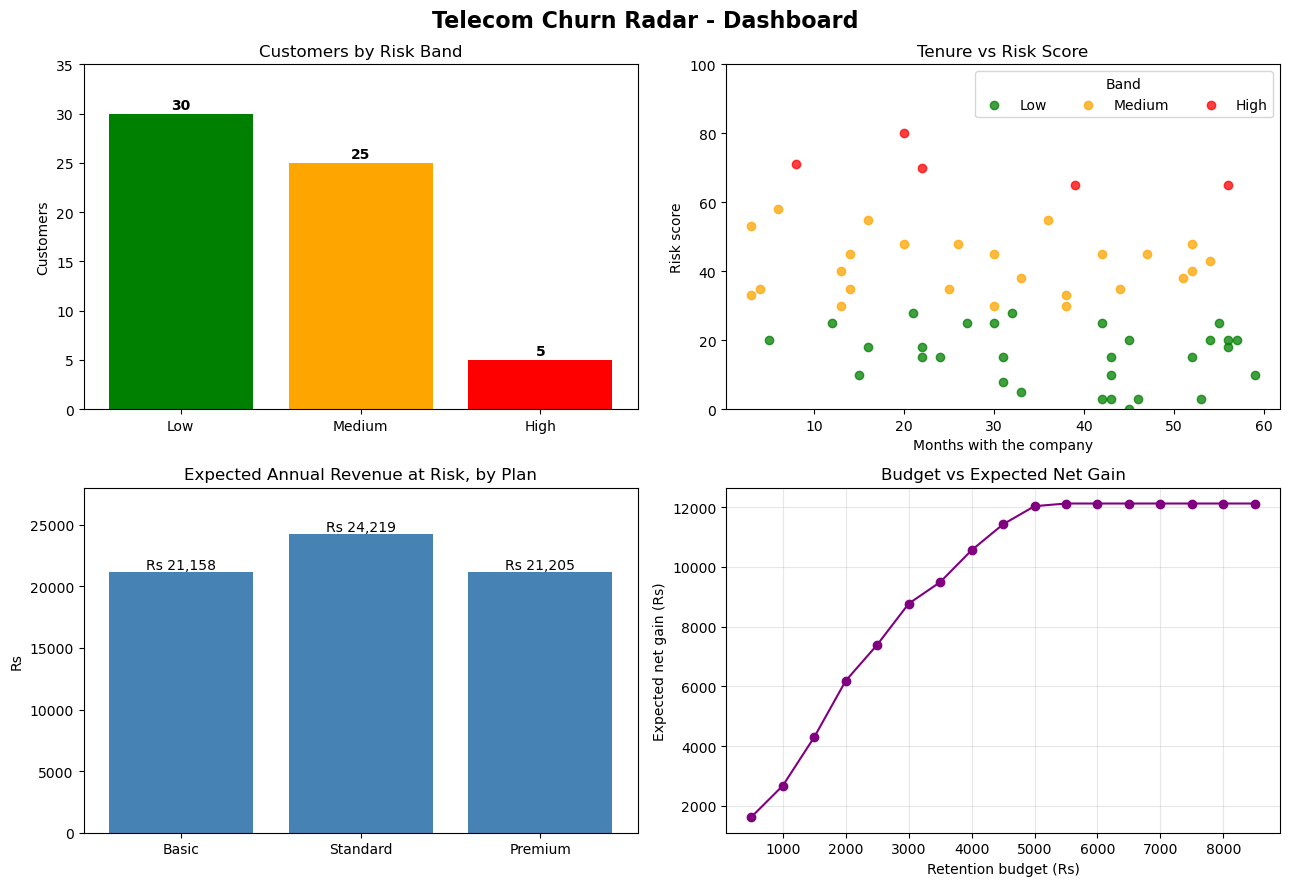

In [10]:
def draw_dashboard():
    colors = {"Low": "green", "Medium": "orange", "High": "red"}
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle("Telecom Churn Radar - Dashboard", fontsize=16, fontweight="bold")

    # Chart 1: how many customers in each risk band
    counts = [low_count, medium_count, high_count]
    axes[0][0].bar(risk_labels, counts, color=["green", "orange", "red"])
    for i in range(3):
        axes[0][0].text(i, counts[i] + 0.5, str(counts[i]), ha="center", fontweight="bold")
    axes[0][0].set_ylim(0, 35)
    axes[0][0].set_title("Customers by Risk Band")
    axes[0][0].set_ylabel("Customers")

    # Chart 2: tenure vs risk score
    for band in risk_labels:
        xs = []
        ys = []
        for i in range(len(customer_ids)):
            if bands[i] == band:
                xs.append(tenures[i])
                ys.append(scores[i])
        axes[0][1].scatter(xs, ys, color=colors[band], label=band, alpha=0.75)
    axes[0][1].set_title("Tenure vs Risk Score")
    axes[0][1].set_xlabel("Months with the company")
    axes[0][1].set_ylabel("Risk score")
    axes[0][1].set_ylim(0, 100)
    axes[0][1].legend(title="Band", loc="upper right", ncol=3)

    # Chart 3: expected revenue at risk by plan
    plan_risk = [basic_risk, standard_risk, premium_risk]
    axes[1][0].bar(plan_names, plan_risk, color="steelblue")
    for i in range(3):
        axes[1][0].text(i, plan_risk[i], f"Rs {plan_risk[i]:,.0f}", ha="center", va="bottom")
    axes[1][0].set_ylim(0, 28000)
    axes[1][0].set_title("Expected Annual Revenue at Risk, by Plan")
    axes[1][0].set_ylabel("Rs")

    # Chart 4: what extra budget buys (diminishing returns)
    budgets = []
    gains = []
    for budget in range(500, 8501, 500):
        chosen, spent, total_net = select_customers(budget)
        budgets.append(budget)
        gains.append(total_net)
    axes[1][1].plot(budgets, gains, marker="o", color="purple")
    axes[1][1].set_title("Budget vs Expected Net Gain")
    axes[1][1].set_xlabel("Retention budget (Rs)")
    axes[1][1].set_ylabel("Expected net gain (Rs)")
    axes[1][1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("churn_dashboard.png", dpi=120)
    plt.show()


draw_dashboard()

In [11]:
def executive_summary():
    today = datetime.date.today().strftime("%d %B %Y")
    high_share = high_count / len(customer_ids) * 100
    header("EXECUTIVE SUMMARY")
    print(f"Company : {COMPANY}")
    print(f"Date    : {today}")
    line()
    print(f"* {high_count} of {len(customer_ids)} customers ({high_share:.0f}%) are High risk.")
    print(f"* Expected revenue at risk is Rs {revenue_at_risk:,.0f} a year.")

    if high_share >= 25:
        print("* Churn pressure is HIGH: start a company-wide retention drive.")
    elif high_share >= 10:
        print("* Churn pressure is MODERATE: target the High and Medium customers.")
    else:
        print("* Churn pressure is LOW: keep watching the early-warning signs.")

    biggest_name = "Basic"
    biggest_value = basic_risk
    if standard_risk > biggest_value:
        biggest_name = "Standard"
        biggest_value = standard_risk
    if premium_risk > biggest_value:
        biggest_name = "Premium"
        biggest_value = premium_risk
    print(f"* The {biggest_name} plan carries the most revenue at risk (Rs {biggest_value:,.0f}).")

    chosen, spent, total_net = select_customers(3000)
    print(f"* A Rs 3,000 budget can target {len(chosen)} customers "
          f"for an expected net gain of Rs {total_net:,.0f}.")


executive_summary()


                              EXECUTIVE SUMMARY                               
Company : TeleConnect (a Jio/Airtel-style telecom operator)
Date    : 04 November 2026
------------------------------------------------------------------------------
* 5 of 60 customers (8%) are High risk.
* Expected revenue at risk is Rs 66,581 a year.
* Churn pressure is LOW: keep watching the early-warning signs.
* The Standard plan carries the most revenue at risk (Rs 24,219).
* A Rs 3,000 budget can target 12 customers for an expected net gain of Rs 8,769.
